# 03 · Model Training, Time Validation and Prediction

This notebook uses the derived files from Notebook 02. It performs four-tier feature ablation, baseline and model comparisons, optional Optuna tuning, one independent temporal holdout evaluation, retraining on the full training set, and row-level test prediction.

**Validation design**: Fit on 2021–2022 → select models/features/parameters using 2023 → evaluate on an independent 2024–2025-03 holdout → retrain the fixed configuration on all 2021–2025-03 data.
The local holdout has labels, whereas the Kaggle test set does not; these two datasets are explicitly distinguished.

The full dataset is used by default. `QUICK_MODE` is intended only to check that the code runs successfully. Its outputs are saved separately and clearly labeled, and should not be used as formal experimental results.


In [1]:
from pathlib import Path
import os
import json
import re
import hashlib
import platform
import importlib.metadata as package_metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from IPython.display import display

SEED = 42
rng = np.random.default_rng(SEED)
pd.set_option('display.max_columns', 100)
sns.set_theme(style='whitegrid', context='notebook')

def locate_project_root():
    override = os.environ.get('HDB_PROJECT_ROOT')
    candidates = [Path(override).expanduser().resolve()] if override else [Path.cwd(), *Path.cwd().parents]
    for candidate in candidates:
        if (candidate / 'data' / 'raw' / 'train.csv').is_file():
            return candidate
    raise FileNotFoundError('Put train.csv and test.csv in PROJECT/data/raw/. Open this notebook from PROJECT or PROJECT/notebooks/.')

ROOT = locate_project_root()
RAW = ROOT / 'data' / 'raw'
PROCESSED = ROOT / 'data' / 'processed'
OUTPUTS = ROOT / 'outputs'
for directory in [PROCESSED, OUTPUTS]:
    directory.mkdir(parents=True, exist_ok=True)

FILES = ['train.csv', 'test.csv', 'sg-hdb-block.csv', 'sg-mrt-stations.csv',
         'sg-shopping-malls.csv', 'sg-schools.csv', 'sg-coe-prices.csv', 'sg-stock-prices.csv']

def raw_path(name):
    candidates = [RAW / name, RAW / 'auxiliary-data' / name]
    for candidate in candidates:
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(f'Missing {name}: expected in {RAW} or {RAW / "auxiliary-data"}.')

def load_raw(name):
    # Preserve identifiers such as 090034 and 321A as text.
    return pd.read_csv(raw_path(name), dtype={'BLOCK': 'string', 'POSTAL_CODE': 'string'})

def clean_text(series):
    return series.astype('string').str.normalize('NFKC').str.strip().str.lower().str.replace(r'\s+', ' ', regex=True)

def canonical_flat_type(series):
    return clean_text(series).str.replace(r'[\s-]*room\b', '-room', regex=True)

def canonical_keys(frame):
    out = frame.copy()
    for column in ['TOWN', 'BLOCK', 'STREET']:
        if column in out:
            out[column] = clean_text(out[column])
    if 'FLAT_TYPE' in out:
        out['FLAT_TYPE'] = canonical_flat_type(out['FLAT_TYPE'])
    return out

def parse_amount(series):
    return pd.to_numeric(series.astype('string').str.replace(r'[$,\s]', '', regex=True), errors='coerce')

def file_sha256(path):
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

print('Project:', ROOT)
print('Python:', platform.python_version())


Project: d:\AppData\NUS\Sem1\5228 Knowledge Discovery and Data Mining\cs5228-hdb-rent-prediction
Python: 3.12.15


## 1. Experiment Configuration

**RMSE** is used for model selection by default, while MAE, RMSLE, and R² are also reported.


In [2]:
import time
import copy
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_squared_log_error, r2_score
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

QUICK_MODE = os.environ.get('HDB_QUICK', '0') == '1'   # Default: full data
PRIMARY_METRIC = 'RMSE'  # RMSE, MAE or RMSLE
MACRO_POLICY = 'fixed_origin'  # Alternative: rolling_monthly, a different information assumption
VALID_START = pd.Timestamp('2023-01-01')
HOLDOUT_START = pd.Timestamp('2024-01-01')
N_JOBS = min(8, os.cpu_count() or 1)
RUN_ABLATION = True
RUN_OPTUNA = True
OPTUNA_TRIALS = 10
RUN_ROLLING_BACKTEST = False
RUN_SHAP = False
RUN_GROUP_COMBINATIONS = True
GROUP_COMBO_USE_BEST_PARAMS = True  # Freeze the better default/tuned candidate's parameters.
GROUP_COMBO_REQUIRE_CORE = False   # False: 15 combinations; True: 8 containing core.
SUBMISSION_TARGET_COLUMN = None  # Set only if the real template has an ambiguous target name
assert PRIMARY_METRIC in ['RMSE', 'MAE', 'RMSLE']
assert MACRO_POLICY in ['fixed_origin', 'rolling_monthly']

RUN_NAME = ('quick' if QUICK_MODE else 'full') + '_' + MACRO_POLICY
RUN_DIR = OUTPUTS / 'training' / RUN_NAME
MODEL_DIR = RUN_DIR / 'models'
SUBMISSION_DIR = ROOT / 'submissions' / RUN_NAME
for directory in [RUN_DIR, MODEL_DIR, SUBMISSION_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
print('Mode:', RUN_NAME, '| Threads:', N_JOBS, '| Selection metric:', PRIMARY_METRIC)


Mode: full_fixed_origin | Threads: 8 | Selection metric: RMSE


## 2. Loading Features and Verifying Provenance and Row Order

If the raw CSV files have changed, rerun feature engineering. Outdated derived features must not be used.


In [3]:
metadata_path = PROCESSED / 'feature_metadata.json'
if not metadata_path.is_file():
    raise FileNotFoundError('Run 02_feature_engineering.ipynb first.')
feature_meta = json.loads(metadata_path.read_text(encoding='utf-8'))
for name, expected_hash in feature_meta['source_sha256'].items():
    assert file_sha256(raw_path(name)) == expected_hash, f'{name} changed: rerun Notebook 02.'
cat_columns = feature_meta['categorical_features']
read_types = {column: 'string' for column in cat_columns}
train_features = pd.read_csv(PROCESSED / 'train_features.csv', dtype=read_types, parse_dates=['rent_approval_date'])
test_features = pd.read_csv(PROCESSED / 'test_features.csv', dtype=read_types, parse_dates=['rent_approval_date'])
targets = pd.read_csv(PROCESSED / 'train_targets.csv')
macro = pd.read_csv(PROCESSED / 'macro_monthly.csv', parse_dates=['source_month']).set_index('source_month').sort_index()
assert np.array_equal(train_features.row_id, targets.row_id)
assert train_features.row_id.is_unique and test_features.row_id.is_unique
assert list(train_features.columns) == list(test_features.columns)
assert 'monthly_rent' not in train_features
y = targets.set_index('row_id').monthly_rent
feature_sets = feature_meta['feature_sets']
print('Rows:', len(train_features), 'train /', len(test_features), 'test')


Rows: 150000 train / 50000 test


## 3. Aligning Macroeconomic Information with Each Forecast Origin

For rental month t, only completed economic data from month t−1 or earlier may be used. In fixed-origin mode, the source month must also be no later than the training-end month.

For example, when training on rents through 2022-12 and predicting all of 2023, macroeconomic observations from 2023 are excluded from the validation features.
Historical training rows still use information from their respective preceding months; rents or macroeconomic data from future rows are not filled back into the past.

`rolling_monthly` assumes that newly available macroeconomic data from preceding months can be accessed when making each month's predictions. This differs from predicting all future months from a single fixed origin. Even in rolling mode, test-set rents are not used to update the model.


In [4]:
def attach_macro(frame, origin_month):
    out = frame.copy()
    requested = out.rent_approval_date - pd.offsets.MonthBegin(1)
    if MACRO_POLICY == 'fixed_origin':
        requested = requested.where(requested <= origin_month, origin_month)
    aligned = macro.reindex(pd.DatetimeIndex(requested)).reset_index(drop=True)
    out = pd.concat([out.reset_index(drop=True), aligned], axis=1)
    out['macro_source_month'] = pd.DatetimeIndex(requested)
    assert out.macro_source_month.lt(out.rent_approval_date).all()
    if MACRO_POLICY == 'fixed_origin':
        assert out.macro_source_month.le(origin_month).all()
    return out

def cap_rows(frame, limit):
    return frame.sample(min(limit, len(frame)), random_state=SEED).sort_values('row_id').reset_index(drop=True)

fit_raw = train_features[train_features.rent_approval_date < VALID_START].copy()
valid_raw = train_features[(train_features.rent_approval_date >= VALID_START) &
                           (train_features.rent_approval_date < HOLDOUT_START)].copy()
holdout_raw = train_features[train_features.rent_approval_date >= HOLDOUT_START].copy()
assert len(fit_raw) and len(valid_raw) and len(holdout_raw)
assert fit_raw.rent_approval_date.max() < valid_raw.rent_approval_date.min()
assert valid_raw.rent_approval_date.max() < holdout_raw.rent_approval_date.min()
if QUICK_MODE:
    fit_raw = cap_rows(fit_raw, 12000)
    valid_raw = cap_rows(valid_raw, 5000)
    holdout_raw = cap_rows(holdout_raw, 5000)

tuning_origin = fit_raw.rent_approval_date.max()
fit_data = attach_macro(fit_raw, tuning_origin)
valid_data = attach_macro(valid_raw, tuning_origin)
y_fit = y.loc[fit_data.row_id].to_numpy()
y_valid = y.loc[valid_data.row_id].to_numpy()
split_summary = pd.DataFrame([
    {'split': name, 'rows_used': len(frame), 'first_month': frame.rent_approval_date.min().strftime('%Y-%m'),
     'last_month': frame.rent_approval_date.max().strftime('%Y-%m')}
    for name, frame in [('fit', fit_raw), ('validation', valid_raw), ('independent_holdout', holdout_raw)]
])
display(split_summary)
print('Validation macro source month maximum:', valid_data.macro_source_month.max())


,split,rows_used,first_month,last_month
0,fit,70183,2021-01,2022-12
1,validation,35654,2023-01,2023-12
2,independent_holdout,44163,2024-01,2025-03


Validation macro source month maximum: 2022-12-01 00:00:00


## 4. Within-fold Preprocessing, Model Construction, and Evaluation Functions

- Ridge / Random Forest / XGBoost / LightGBM: Imputation is fitted within the training fold, categorical variables are one-hot encoded, and rare categories are grouped using `min_frequency`.
- CatBoost: Categorical meaning is preserved rather than arbitrarily encoding categories such as Town as continuous integers. Categorical feature indices are generated from the fixed column order after preprocessing.
- All candidates use the same data splits, target scale, and evaluation functions. Negative predictions are clipped to 0 consistently; predictions are not clipped using the observed range of true rents.
- Fixed tree counts are used for reproducibility. This version does not use the independent holdout for early stopping.


In [5]:
def prepared_inputs(frame, columns):
    out = frame[columns].copy()
    for column in columns:
        if column in cat_columns:
            out[column] = out[column].astype('string').fillna('__MISSING__').astype(str)
        else:
            out[column] = pd.to_numeric(out[column], errors='coerce').replace([np.inf, -np.inf], np.nan)
    return out

def build_pipeline(kind, columns, params=None):
    cats = [column for column in columns if column in cat_columns]
    nums = [column for column in columns if column not in cats]
    if kind == 'catboost':
        preprocessor = ColumnTransformer([
            ('num', SimpleImputer(strategy='median', keep_empty_features=True), nums),
            ('cat', 'passthrough', cats)
        ], sparse_threshold=0)
        defaults = dict(iterations=80 if QUICK_MODE else 400, depth=6, learning_rate=.05,
                        loss_function='RMSE', random_seed=SEED, thread_count=N_JOBS,
                        verbose=False, allow_writing_files=False, cat_features=list(range(len(nums), len(columns))))
        defaults.update(params or {})
        estimator = CatBoostRegressor(**defaults)
    else:
        numeric_pipe = Pipeline([
            ('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
            ('scale', StandardScaler(with_mean=False))
        ])
        preprocessor = ColumnTransformer([
            ('num', numeric_pipe, nums),
            ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=10, sparse_output=True), cats)
        ], sparse_threshold=1.0)
        if kind == 'ridge':
            defaults = dict(alpha=100., solver='lsqr', tol=1e-4)
            defaults.update(params or {}); estimator = Ridge(**defaults)
        elif kind == 'random_forest':
            defaults = dict(n_estimators=30 if QUICK_MODE else 100, max_depth=16, min_samples_leaf=8,
                            max_features=.7, n_jobs=N_JOBS, random_state=SEED)
            defaults.update(params or {}); estimator = RandomForestRegressor(**defaults)
        elif kind == 'xgboost':
            defaults = dict(n_estimators=80 if QUICK_MODE else 400, max_depth=6, learning_rate=.05,
                            subsample=.8, colsample_bytree=.8, min_child_weight=10, reg_lambda=5,
                            objective='reg:squarederror', tree_method='hist', n_jobs=N_JOBS, random_state=SEED)
            defaults.update(params or {}); estimator = XGBRegressor(**defaults)
        elif kind == 'lightgbm':
            defaults = dict(n_estimators=80 if QUICK_MODE else 400, num_leaves=31, learning_rate=.05,
                            min_child_samples=30, colsample_bytree=.8, subsample=.8, subsample_freq=1,
                            reg_lambda=5, n_jobs=N_JOBS, random_state=SEED, verbosity=-1)
            defaults.update(params or {}); estimator = LGBMRegressor(**defaults)
        else:
            raise ValueError(kind)
    return Pipeline([('preprocess', preprocessor), ('model', estimator)])

def fit_bundle(spec, frame, labels):
    columns = list(feature_sets[spec['feature_set']])
    # Avoid very wide address one-hot matrices in the Random Forest baseline.
    # Geographic coordinates and region/subzone information still describe location.
    if spec['kind'] == 'random_forest':
        columns = [c for c in columns if c not in ['building_id', 'street']]
    bundle = {'spec': copy.deepcopy(spec), 'columns': columns}
    if spec['kind'] == 'global_mean':
        bundle['global_mean'] = float(np.mean(labels))
    elif spec['kind'] == 'town_flat_mean':
        history = frame[['town', 'flat_type']].copy()
        history['target'] = np.asarray(labels)
        mean = float(np.mean(labels))
        grouped = history.groupby(['town', 'flat_type']).target.agg(['mean', 'count'])
        grouped['smoothed'] = (grouped['count'] * grouped['mean'] + 20 * mean) / (grouped['count'] + 20)
        bundle.update(global_mean=mean, group_means=grouped.smoothed.to_dict())
    else:
        pipe = build_pipeline(spec['kind'], columns, spec.get('params'))
        pipe.fit(prepared_inputs(frame, columns), labels)
        bundle['pipeline'] = pipe
    return bundle

def predict_bundle(bundle, frame):
    kind = bundle['spec']['kind']
    if kind == 'global_mean':
        prediction = np.full(len(frame), bundle['global_mean'])
    elif kind == 'town_flat_mean':
        prediction = np.array([bundle['group_means'].get((town, flat), bundle['global_mean'])
                              for town, flat in zip(frame.town, frame.flat_type)])
    else:
        prediction = bundle['pipeline'].predict(prepared_inputs(frame, bundle['columns']))
    prediction = np.maximum(np.asarray(prediction, dtype=float), 0.)
    assert prediction.shape == (len(frame),) and np.isfinite(prediction).all()
    return prediction

def regression_metrics(actual, prediction):
    return {'RMSE': float(np.sqrt(mean_squared_error(actual, prediction))),
            'MAE': float(mean_absolute_error(actual, prediction)),
            'RMSLE': float(np.sqrt(mean_squared_log_error(actual, prediction))),
            'R2': float(r2_score(actual, prediction))}

def evaluate_spec(spec, fitting, labels, evaluation, actual):
    start = time.perf_counter()
    bundle = fit_bundle(spec, fitting, labels)
    prediction = predict_bundle(bundle, evaluation)
    row = {'model': spec['name'], 'kind': spec['kind'], 'feature_set': spec['feature_set'],
           **regression_metrics(actual, prediction), 'input_features': len(bundle['columns']), 'fit_predict_seconds': time.perf_counter() - start}
    return row, bundle, prediction


## 5. Four-tier Feature Ablation

The same configuration and parameters are used throughout, with feature groups added progressively to compare their incremental value. The best tier is selected solely using the 2023 validation score.


In [6]:
MODEL_KINDS = ['ridge', 'random_forest', 'xgboost', 'lightgbm', 'catboost']
FEATURE_SET_NAMES = ['core', 'building', 'amenities', 'macro']

ablation_rows = []
best_feature_rows = []
selected_feature_sets = {kind: 'amenities' for kind in MODEL_KINDS}
ablation_results = pd.DataFrame()
best_features_by_model = pd.DataFrame()

if RUN_ABLATION:
    for kind in MODEL_KINDS:
        model_rows = []
        print(f'\nFeature ablation: {kind}')
        for feature_set in FEATURE_SET_NAMES:
            spec = {'name': f'{kind}_{feature_set}', 'kind': kind,
                    'feature_set': feature_set, 'params': {}}
            row, bundle, prediction = evaluate_spec(
                spec, fit_data, y_fit, valid_data, y_valid
            )
            model_rows.append(row)
            ablation_rows.append(row)
            print(f"  {feature_set}: {PRIMARY_METRIC}={row[PRIMARY_METRIC]:.3f}")
            del bundle, prediction

        model_results = pd.DataFrame(model_rows).sort_values(
            PRIMARY_METRIC, kind='stable'
        ).reset_index(drop=True)
        best = model_results.iloc[0]
        selected_feature_sets[kind] = str(best['feature_set'])
        best_feature_rows.append(best.to_dict())
        model_results.to_csv(RUN_DIR / f'feature_ablation_{kind}.csv', index=False)
        display(model_results.round(4))

    ablation_results = pd.DataFrame(ablation_rows)
    best_features_by_model = pd.DataFrame(best_feature_rows).sort_values(
        PRIMARY_METRIC, kind='stable'
    ).reset_index(drop=True)
    ablation_results.to_csv(RUN_DIR / 'feature_ablation.csv', index=False)
    best_features_by_model.to_csv(RUN_DIR / 'best_features_by_model.csv', index=False)
    display(best_features_by_model.round(4))
else:
    print('Ablation skipped; using amenities for every model.')

print('Selected feature sets:', selected_feature_sets)



Feature ablation: ridge
  core: RMSE=643.794
  building: RMSE=634.065
  amenities: RMSE=633.384
  macro: RMSE=630.154


,model,kind,feature_set,RMSE,MAE,RMSLE,R2,input_features,fit_predict_seconds
0,ridge_macro,ridge,macro,630.1536,514.8518,0.2332,0.2957,71,1.8303
1,ridge_amenities,ridge,amenities,633.3844,513.0122,0.2347,0.2885,41,1.1491
2,ridge_building,ridge,building,634.0655,513.4425,0.2349,0.2869,28,0.8916
3,ridge_core,ridge,core,643.7941,519.5320,0.2375,0.2649,14,0.3364



Feature ablation: random_forest
  core: RMSE=711.080
  building: RMSE=697.922
  amenities: RMSE=699.129
  macro: RMSE=672.756


,model,kind,feature_set,RMSE,MAE,RMSLE,R2,input_features,fit_predict_seconds
0,random_forest_macro,random_forest,macro,672.7560,560.5757,0.2417,0.1973,69,84.5152
1,random_forest_building,random_forest,building,697.9223,581.1723,0.2486,0.1361,26,24.8877
2,random_forest_amenities,random_forest,amenities,699.1287,581.7356,0.2489,0.1331,39,40.5769
3,random_forest_core,random_forest,core,711.0801,589.1895,0.2516,0.1032,14,9.7209



Feature ablation: xgboost
  core: RMSE=694.923
  building: RMSE=689.914
  amenities: RMSE=699.193
  macro: RMSE=688.781


...

,model,kind,feature_set,RMSE,MAE,RMSLE,R2,input_features,fit_predict_seconds
0,lightgbm_macro,lightgbm,macro,669.7499,557.7944,0.2407,0.2044,71,2.1246
1,lightgbm_amenities,lightgbm,amenities,682.2721,567.4108,0.2443,0.1744,41,1.6538
2,lightgbm_core,lightgbm,core,691.1813,573.8067,0.2464,0.1527,14,0.7140
3,lightgbm_building,lightgbm,building,695.7163,579.5185,0.2479,0.1415,28,1.4553



Feature ablation: catboost
  core: RMSE=670.983
  building: RMSE=662.758
  amenities: RMSE=657.717
  macro: RMSE=655.088


,model,kind,feature_set,RMSE,MAE,RMSLE,R2,input_features,fit_predict_seconds
0,catboost_macro,catboost,macro,655.0881,548.0646,0.2368,0.2389,71,23.0465
1,catboost_amenities,catboost,amenities,657.7167,548.2825,0.2377,0.2327,41,20.7723
2,catboost_building,catboost,building,662.7580,552.3167,0.2390,0.2209,28,20.1405
3,catboost_core,catboost,core,670.9828,558.1511,0.2411,0.2015,14,14.9237


,model,kind,feature_set,RMSE,MAE,RMSLE,R2,input_features,fit_predict_seconds
0,ridge_macro,ridge,macro,630.1536,514.8518,0.2332,0.2957,71,1.8303
1,catboost_macro,catboost,macro,655.0881,548.0646,0.2368,0.2389,71,23.0465
2,lightgbm_macro,lightgbm,macro,669.7499,557.7944,0.2407,0.2044,71,2.1246
3,random_forest_macro,random_forest,macro,672.7560,560.5757,0.2417,0.1973,69,84.5152
4,xgboost_macro,xgboost,macro,688.7808,574.6477,0.2456,0.1586,71,2.2323


Selected feature sets: {'ridge': 'macro', 'random_forest': 'macro', 'xgboost': 'macro', 'lightgbm': 'macro', 'catboost': 'macro'}


## 6. Baseline and Model Comparison

Candidates include the global mean, a smoothed Town × flat-type mean, Ridge, Random Forest, XGBoost, LightGBM, and CatBoost.
Group means are calculated entirely from rents in the fitting period. Unseen groups fall back to the global mean from that period.

To control training cost, Random Forest excludes the high-cardinality building_id / street features while retaining location features such as latitude/longitude, region, and postal district. This is an explicit model-specific input choice. Other models use all features in the selected tier, and the leaderboard records input_features.

Ridge can extrapolate along numerical time trends. Standard tree ensembles generally assign time values beyond the training range to existing leaves. Their limitations over long forecast horizons should therefore be discussed alongside the observed errors.


In [7]:
specs = [
    {'name': kind, 'kind': kind, 'feature_set': 'core', 'params': {}}
    for kind in ['global_mean', 'town_flat_mean']
] + [
    {'name': kind, 'kind': kind,
     'feature_set': selected_feature_sets[kind], 'params': {}}
    for kind in MODEL_KINDS
]

result_rows, fitted_bundles, validation_predictions = [], {}, {}
for spec in specs:
    row, bundle, prediction = evaluate_spec(
        spec, fit_data, y_fit, valid_data, y_valid
    )
    result_rows.append(row)
    fitted_bundles[spec['name']] = bundle
    validation_predictions[spec['name']] = prediction
    print(f"{spec['name']} | {spec['feature_set']} | "
          f"{PRIMARY_METRIC}={row[PRIMARY_METRIC]:.3f}")

leaderboard = pd.DataFrame(result_rows).sort_values(
    PRIMARY_METRIC, kind='stable'
).reset_index(drop=True)
leaderboard.to_csv(RUN_DIR / 'validation_leaderboard.csv', index=False)
display(leaderboard.round(4))

global_mean | core | RMSE=1045.720
town_flat_mean | core | RMSE=977.334
ridge | macro | RMSE=630.154
random_forest | macro | RMSE=672.756
xgboost | macro | RMSE=688.781


d:\AppData\miniconda3\envs\cs5228\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


lightgbm | macro | RMSE=669.750
catboost | macro | RMSE=655.088


,model,kind,feature_set,RMSE,MAE,RMSLE,R2,input_features,fit_predict_seconds
0,ridge,ridge,macro,630.1536,514.8518,0.2332,0.2957,71,1.8678
1,catboost,catboost,macro,655.0881,548.0646,0.2368,0.2389,71,21.4819
2,lightgbm,lightgbm,macro,669.7499,557.7944,0.2407,0.2044,71,1.9933
3,random_forest,random_forest,macro,672.7560,560.5757,0.2417,0.1973,69,79.4754
4,xgboost,xgboost,macro,688.7808,574.6477,0.2456,0.1586,71,2.0986
5,town_flat_mean,town_flat_mean,core,977.3339,831.3089,0.3438,-0.6941,14,0.0325
6,global_mean,global_mean,core,1045.7199,863.5839,0.3632,-0.9395,14,0.0025


## 7. Optional Optuna Tuning: Tuning-period Validation Only

When enabled, Optuna optimizes different models' depth, learning rate, tree count, regularization or other parameters.

In [8]:
def suggest_model_params(trial, kind):
    if kind == 'ridge':
        return {'alpha': trial.suggest_float('alpha', 1e-2, 1e5, log=True)}

    if kind == 'random_forest':
        return {
            'n_estimators': trial.suggest_int(
                'n_estimators', 30 if QUICK_MODE else 100,
                150 if QUICK_MODE else 400, step=30 if QUICK_MODE else 100),
            'max_depth': trial.suggest_int('max_depth', 8, 24, step=4),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 2, 20),
            'max_features': trial.suggest_float('max_features', .4, 1.)
        }

    if kind not in ['xgboost', 'lightgbm', 'catboost']:
        raise ValueError(kind)

    iteration_key = 'iterations' if kind == 'catboost' else 'n_estimators'
    params = {
        iteration_key: trial.suggest_int(
            iteration_key, 80 if QUICK_MODE else 200,
            240 if QUICK_MODE else 800, step=40 if QUICK_MODE else 100),
        'learning_rate': trial.suggest_float('learning_rate', .02, .15, log=True)
    }

    if kind == 'catboost':
        params.update({
            'depth': trial.suggest_int('depth', 4, 8),
            'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1., 20., log=True)
        })
        return params

    params.update({
        'subsample': trial.suggest_float('subsample', .6, 1.),
        'colsample_bytree': trial.suggest_float('colsample_bytree', .6, 1.),
        'reg_lambda': trial.suggest_float('reg_lambda', .1, 30., log=True)
    })
    if kind == 'xgboost':
        params.update({
            'max_depth': trial.suggest_int('max_depth', 3, 9),
            'min_child_weight': trial.suggest_float('min_child_weight', 1., 30., log=True)
        })
    else:
        params.update({
            'num_leaves': trial.suggest_categorical('num_leaves', [15, 31, 63]),
            'min_child_samples': trial.suggest_int('min_child_samples', 10, 80, step=10)
        })
    return params


def make_objective(kind, feature_set):
    def objective(trial):
        spec = {'name': f'{kind}_trial', 'kind': kind,
                'feature_set': feature_set,
                'params': suggest_model_params(trial, kind)}
        row, bundle, prediction = evaluate_spec(
            spec, fit_data, y_fit, valid_data, y_valid
        )
        del bundle, prediction
        return float(row[PRIMARY_METRIC])
    return objective


studies, tuned_specs, tuning_rows = {}, {}, []

# Remove previous tuned candidates when rerunning this cell.
tuned_names = {f'{kind}_optuna' for kind in MODEL_KINDS}
result_rows = [row for row in result_rows if row['model'] not in tuned_names]
for name in tuned_names:
    fitted_bundles.pop(name, None)
    validation_predictions.pop(name, None)

if RUN_OPTUNA:
    import optuna
    if OPTUNA_TRIALS < 1:
        raise ValueError('OPTUNA_TRIALS must be at least 1.')

    for kind in MODEL_KINDS:
        feature_set = selected_feature_sets[kind]
        print(f'\nOptuna: {kind} | features={feature_set}')
        study = optuna.create_study(
            direction='minimize',
            sampler=optuna.samplers.TPESampler(
                seed=SEED, n_startup_trials=min(5, max(1, OPTUNA_TRIALS // 3))
            )
        )
        study.optimize(
            make_objective(kind, feature_set),
            n_trials=OPTUNA_TRIALS, n_jobs=1, gc_after_trial=True
        )
        studies[kind] = study
        study.trials_dataframe().to_csv(
            RUN_DIR / f'optuna_trials_{kind}.csv', index=False
        )

        # Refit one best-trial candidate for each model.
        tuned_spec = {
            'name': f'{kind}_optuna', 'kind': kind,
            'feature_set': feature_set, 'params': dict(study.best_params)
        }
        tuned_specs[kind] = copy.deepcopy(tuned_spec)
        row, bundle, prediction = evaluate_spec(
            tuned_spec, fit_data, y_fit, valid_data, y_valid
        )
        result_rows.append(row)
        tuning_rows.append(row)
        fitted_bundles[tuned_spec['name']] = bundle
        validation_predictions[tuned_spec['name']] = prediction
        print('Best searched parameters:', study.best_params)
        print(f"{PRIMARY_METRIC}={row[PRIMARY_METRIC]:.3f}")

        # Checkpoint parameters after each model finishes.
        (RUN_DIR / 'optuna_best_specs.json').write_text(
            json.dumps(tuned_specs, indent=2), encoding='utf-8'
        )

    tuning_results = pd.DataFrame(tuning_rows).sort_values(
        PRIMARY_METRIC, kind='stable'
    ).reset_index(drop=True)
    tuning_results.to_csv(RUN_DIR / 'optuna_results.csv', index=False)
else:
    tuning_results = pd.DataFrame()
    print('Optuna skipped; set RUN_OPTUNA=True to enable.')

# Retain both default and tuned candidates in the final ranking.
leaderboard = pd.DataFrame(result_rows).sort_values(
    PRIMARY_METRIC, kind='stable'
).reset_index(drop=True)
leaderboard.to_csv(RUN_DIR / 'validation_leaderboard.csv', index=False)
display(leaderboard.round(4))


d:\AppData\miniconda3\envs\cs5228\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-10-18 21:43:48,645] A new study created in memory with name: no-name-c89249a0-2156-4488-9d66-56d5bbc5e673



Optuna: ridge | features=macro


[I 2026-10-18 21:43:51,297] Trial 0 finished with value: 626.14628734296 and parameters: {'alpha': 4.185822729546974}. Best is trial 0 with value: 626.14628734296.
[I 2026-10-18 21:43:52,601] Trial 1 finished with value: 697.1702402796467 and parameters: {'alpha': 45185.60951024107}. Best is trial 0 with value: 626.14628734296.
[I 2026-10-18 21:43:54,096] Trial 2 finished with value: 638.6019608371972 and parameters: {'alpha': 1330.3245101522919}. Best is trial 0 with value: 626.14628734296.
[I 2026-10-18 21:43:57,083] Trial 3 finished with value: 627.3023958163642 and parameters: {'alpha': 0.08331126851857817}. Best is trial 0 with value: 626.14628734296.
[I 2026-10-18 21:44:00,172] Trial 4 finished with value: 626.8112777593424 and parameters: {'alpha': 1.1258052825633105}. Best is trial 0 with value: 626.14628734296.
[I 2026-10-18 21:44:02,397] Trial 5 finished with value: 627.7827079126146 and parameters: {'alpha': 30.30489745127909}. Best is trial 0 with value: 626.14628734296.
[I

Best searched parameters: {'alpha': 4.185822729546974}
RMSE=626.146

Optuna: random_forest | features=macro


[I 2026-10-18 21:46:53,643] Trial 0 finished with value: 671.3792775742984 and parameters: {'n_estimators': 200, 'max_depth': 24, 'min_samples_leaf': 15, 'max_features': 0.759195090518222}. Best is trial 0 with value: 671.3792775742984.
[I 2026-10-18 21:47:16,762] Trial 1 finished with value: 679.6495763297768 and parameters: {'n_estimators': 100, 'max_depth': 8, 'min_samples_leaf': 3, 'max_features': 0.9197056874649611}. Best is trial 0 with value: 671.3792775742984.
[I 2026-10-18 22:01:32,056] Trial 2 finished with value: 677.0176991654072 and parameters: {'n_estimators': 300, 'max_depth': 20, 'min_samples_leaf': 2, 'max_features': 0.9819459112971965}. Best is trial 0 with value: 671.3792775742984.
[I 2026-10-18 22:03:12,667] Trial 3 finished with value: 669.5135974883866 and parameters: {'n_estimators': 200, 'max_depth': 24, 'min_samples_leaf': 19, 'max_features': 0.5194695358956554}. Best is trial 3 with value: 669.5135974883866.
[I 2026-10-18 22:04:49,274] Trial 4 finished with va

...

d:\AppData\miniconda3\envs\cs5228\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
[I 2026-10-18 22:21:18,981] Trial 0 finished with value: 709.6552396117502 and parameters: {'n_estimators': 400, 'learning_rate': 0.1358198535217987, 'subsample': 0.892797576724562, 'colsample_bytree': 0.8394633936788146, 'reg_lambda': 0.24348773534554594, 'num_leaves': 63, 'min_child_samples': 50}. Best is trial 0 with value: 709.6552396117502.
d:\AppData\miniconda3\envs\cs5228\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
[I 2026-10-18 22:21:22,104] Trial 1 finished with value: 702.065352043693 and parameters: {'n_estimators': 600, 'learning_rate': 0.020846957895078073, 'subsample': 0.9879639408647978, 'colsample_bytree': 0.9329770563201687, 'reg_lambda': 0.3357296705

Best searched parameters: {'n_estimators': 300, 'learning_rate': 0.07173990592988709, 'subsample': 0.7485880144689303, 'colsample_bytree': 0.7667698433310003, 'reg_lambda': 2.9073850649959905, 'num_leaves': 15, 'min_child_samples': 30}
RMSE=651.437

Optuna: catboost | features=macro


[I 2026-10-18 22:22:05,369] Trial 0 finished with value: 706.1888494361169 and parameters: {'iterations': 400, 'learning_rate': 0.1358198535217987, 'depth': 7, 'l2_leaf_reg': 6.009974718380312}. Best is trial 0 with value: 706.1888494361169.
[I 2026-10-18 22:22:16,673] Trial 1 finished with value: 659.5177839681952 and parameters: {'iterations': 300, 'learning_rate': 0.027386388058464273, 'depth': 4, 'l2_leaf_reg': 13.39433470675048}. Best is trial 1 with value: 659.5177839681952.
[I 2026-10-18 22:22:37,471] Trial 2 finished with value: 648.8611751684095 and parameters: {'iterations': 600, 'learning_rate': 0.08329844231669226, 'depth': 4, 'l2_leaf_reg': 18.276027831785726}. Best is trial 2 with value: 648.8611751684095.
[I 2026-10-18 22:23:04,706] Trial 3 finished with value: 652.2639889573713 and parameters: {'iterations': 800, 'learning_rate': 0.08646554230420432, 'depth': 4, 'l2_leaf_reg': 1.0552829926879395}. Best is trial 2 with value: 648.8611751684095.
[I 2026-10-18 22:23:34,946

Best searched parameters: {'iterations': 800, 'learning_rate': 0.06404318684890074, 'depth': 5, 'l2_leaf_reg': 10.401153464567013}
RMSE=636.162


,model,kind,feature_set,RMSE,MAE,RMSLE,R2,input_features,fit_predict_seconds
0,ridge_optuna,ridge,macro,626.1463,511.3124,0.2323,0.3046,71,2.6912
1,ridge,ridge,macro,630.1536,514.8518,0.2332,0.2957,71,1.8678
2,catboost_optuna,catboost,macro,636.1625,529.4245,0.2327,0.2822,71,34.9988
3,xgboost_optuna,xgboost,macro,639.3306,529.2931,0.2337,0.2750,71,2.1405
4,lightgbm_optuna,lightgbm,macro,651.4368,541.6332,0.2362,0.2473,71,1.6217
5,catboost,catboost,macro,655.0881,548.0646,0.2368,0.2389,71,21.4819
6,random_forest_optuna,random_forest,macro,669.5136,558.1960,0.2406,0.2050,69,98.4205
7,lightgbm,lightgbm,macro,669.7499,557.7944,0.2407,0.2044,71,1.9933
8,random_forest,random_forest,macro,672.7560,560.5757,0.2417,0.1973,69,79.4754
9,xgboost,xgboost,macro,688.7808,574.6477,0.2456,0.1586,71,2.0986


In [9]:
# Existing feature_sets are cumulative. Recover four independent feature groups.
group_order = ['core', 'building', 'amenities', 'macro']
cumulative = {name: list(dict.fromkeys(feature_sets[name])) for name in group_order}
feature_groups = {}
seen = set()
for group in group_order:
    if not seen.issubset(cumulative[group]):
        raise ValueError(f'Expected cumulative feature sets; check {group}.')
    feature_groups[group] = [c for c in cumulative[group] if c not in seen]
    seen.update(cumulative[group])

if any(not columns for columns in feature_groups.values()):
    raise ValueError('Each of the four feature groups must contain at least one feature.')

group_combinations = {}
combination_members = {}
for size in range(1, len(group_order) + 1):
    for groups in combinations(group_order, size):
        if GROUP_COMBO_REQUIRE_CORE and 'core' not in groups:
            continue
        name = 'combo__' + '__'.join(groups)
        columns = list(dict.fromkeys(
            column for group in groups for column in feature_groups[group]
        ))
        group_combinations[name] = columns
        combination_members[name] = list(groups)

# fit_bundle looks up feature_sets[spec['feature_set']]. Keep these entries for refits.
feature_sets.update(group_combinations)
for frame in (fit_data, valid_data):
    missing = sorted(seen.difference(frame.columns))
    if missing:
        raise ValueError(f'Input frame is missing features: {missing}')

print('Independent group sizes:', {g: len(c) for g, c in feature_groups.items()})
print('Combinations per model:', len(group_combinations))

# Re-running this cell replaces only candidates belonging to this experiment.
candidate_names = {f'{kind}_group_combo' for kind in MODEL_KINDS}
result_rows = [row for row in result_rows if row['model'] not in candidate_names]
for name in candidate_names:
    fitted_bundles.pop(name, None)
    validation_predictions.pop(name, None)

group_combo_rows = []
group_combo_best_rows = []
group_combo_best_specs = {}
selected_group_feature_sets = {}

if RUN_GROUP_COMBINATIONS:
    for kind in MODEL_KINDS:
        # Choose parameters ONCE per model, then hold them fixed across all combinations.
        params = {}
        parameter_source = 'default'
        if GROUP_COMBO_USE_BEST_PARAMS:
            previous = [
                row for row in result_rows
                if row['kind'] == kind
                and row['model'] in {kind, f'{kind}_optuna'}
            ]
            if previous:
                best_previous = min(previous, key=lambda row: row[PRIMARY_METRIC])
                parameter_source = best_previous['model']
                params = copy.deepcopy(
                    fitted_bundles[parameter_source]['spec'].get('params', {})
                )

        print(f'\nGroup combinations: {kind} | parameters from {parameter_source}')
        model_rows = []
        for feature_set, columns in group_combinations.items():
            spec = {
                'name': f'{kind}__{feature_set}', 'kind': kind,
                'feature_set': feature_set, 'params': copy.deepcopy(params)
            }
            row, bundle, prediction = evaluate_spec(
                spec, fit_data, y_fit, valid_data, y_valid
            )
            row.update(
                groups=' + '.join(combination_members[feature_set]),
                parameter_source=parameter_source
            )
            model_rows.append(row)
            group_combo_rows.append(row)
            print(f"  {row['groups']}: {PRIMARY_METRIC}={row[PRIMARY_METRIC]:.3f}")
            del bundle, prediction  # Search phase retains scores, not fitted models.

        model_results = pd.DataFrame(model_rows).sort_values(
            PRIMARY_METRIC, kind='stable'
        ).reset_index(drop=True)
        model_results.to_csv(RUN_DIR / f'group_combinations_{kind}.csv', index=False)
        best = model_results.iloc[0]
        selected_group_feature_sets[kind] = str(best['feature_set'])

        # Refit exactly one winner for this model, matching the existing workflow.
        best_spec = {
            'name': f'{kind}_group_combo', 'kind': kind,
            'feature_set': str(best['feature_set']), 'params': copy.deepcopy(params)
        }
        row, bundle, prediction = evaluate_spec(
            best_spec, fit_data, y_fit, valid_data, y_valid
        )
        row.update(groups=str(best['groups']), parameter_source=parameter_source)
        result_rows.append(row)
        group_combo_best_rows.append(row)
        fitted_bundles[best_spec['name']] = bundle
        validation_predictions[best_spec['name']] = prediction
        group_combo_best_specs[kind] = copy.deepcopy(best_spec)
        print(f"Selected: {kind} | {row['groups']} | {PRIMARY_METRIC}={row[PRIMARY_METRIC]:.3f}")

    group_combo_results = pd.DataFrame(group_combo_rows).sort_values(
        ['kind', PRIMARY_METRIC], kind='stable'
    ).reset_index(drop=True)
    best_group_combinations = pd.DataFrame(group_combo_best_rows).sort_values(
        PRIMARY_METRIC, kind='stable'
    ).reset_index(drop=True)
    group_combo_results.to_csv(RUN_DIR / 'group_combinations_all.csv', index=False)
    best_group_combinations.to_csv(RUN_DIR / 'best_group_combinations.csv', index=False)

    # Persist column definitions as well as parameters, so custom feature-set names
    # can be reconstructed in a fresh session before calling fit_bundle again.
    (RUN_DIR / 'group_combinations_best_specs.json').write_text(
        json.dumps({
            'parameter_policy': 'best_existing_default_or_tuned' if GROUP_COMBO_USE_BEST_PARAMS else 'default',
            'require_core': GROUP_COMBO_REQUIRE_CORE,
            'feature_groups': feature_groups,
            'feature_sets': group_combinations,
            'best_specs': group_combo_best_specs
        }, indent=2), encoding='utf-8'
    )
    display(best_group_combinations.round(4))
else:
    group_combo_results = pd.DataFrame()
    best_group_combinations = pd.DataFrame()
    print('Feature-group combination experiment skipped.')

leaderboard = pd.DataFrame(result_rows).sort_values(
    PRIMARY_METRIC, kind='stable'
).reset_index(drop=True)
leaderboard.to_csv(RUN_DIR / 'validation_leaderboard.csv', index=False)
display(leaderboard.round(4))

# For the subsequent holdout/refit cell, preserve the winner's complete spec:
# best_name = leaderboard.iloc[0]['model']
# best_spec = copy.deepcopy(fitted_bundles[best_name]['spec'])

Independent group sizes: {'core': 14, 'building': 14, 'amenities': 13, 'macro': 30}
Combinations per model: 15

Group combinations: ridge | parameters from ridge_optuna
  core: RMSE=641.895
  building: RMSE=886.926
  amenities: RMSE=1038.495
  macro: RMSE=753.233
  core + building: RMSE=630.245
  core + amenities: RMSE=638.221
  core + macro: RMSE=638.903
  building + amenities: RMSE=888.818
  building + macro: RMSE=658.889
  amenities + macro: RMSE=743.011
  core + building + amenities: RMSE=630.129
  core + building + macro: RMSE=627.037
  core + amenities + macro: RMSE=635.335
  building + amenities + macro: RMSE=658.417
  core + building + amenities + macro: RMSE=626.146
Selected: ridge | core + building + amenities + macro | RMSE=626.146

Group combinations: random_forest | parameters from random_forest_optuna
  core: RMSE=718.780
  building: RMSE=872.043
  amenities: RMSE=978.006
  macro: RMSE=786.455
  core + building: RMSE=704.589
  core + amenities: RMSE=710.125
  core + macro

d:\AppData\miniconda3\envs\cs5228\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


  core: RMSE=697.428


d:\AppData\miniconda3\envs\cs5228\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


  building: RMSE=880.911


...

  core + building + amenities + macro: RMSE=651.437


d:\AppData\miniconda3\envs\cs5228\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Selected: lightgbm | core + building + amenities + macro | RMSE=651.437

Group combinations: catboost | parameters from catboost_optuna
  core: RMSE=680.337
  building: RMSE=891.456
  amenities: RMSE=996.382
  macro: RMSE=861.458
  core + building: RMSE=647.091
  core + amenities: RMSE=661.461
  core + macro: RMSE=653.865
  building + amenities: RMSE=896.329
  building + macro: RMSE=675.942
  amenities + macro: RMSE=727.368
  core + building + amenities: RMSE=651.021
  core + building + macro: RMSE=642.937
  core + amenities + macro: RMSE=668.033
  building + amenities + macro: RMSE=671.227
  core + building + amenities + macro: RMSE=636.162
Selected: catboost | core + building + amenities + macro | RMSE=636.162


,model,kind,feature_set,RMSE,MAE,RMSLE,R2,input_features,fit_predict_seconds,groups,parameter_source
0,ridge_group_combo,ridge,combo__core__building__amenities__macro,626.1463,511.3124,0.2323,0.3046,71,2.7912,core + building + amenities + macro,ridge_optuna
1,catboost_group_combo,catboost,combo__core__building__amenities__macro,636.1625,529.4245,0.2327,0.2822,71,32.8019,core + building + amenities + macro,catboost_optuna
2,xgboost_group_combo,xgboost,combo__core__building__amenities,637.6676,527.6021,0.2334,0.2788,41,1.7268,core + building + amenities,xgboost_optuna
3,lightgbm_group_combo,lightgbm,combo__core__building__amenities__macro,651.4368,541.6332,0.2362,0.2473,71,1.7851,core + building + amenities + macro,lightgbm_optuna
4,random_forest_group_combo,random_forest,combo__core__building__amenities__macro,669.5136,558.1960,0.2406,0.2050,69,98.1019,core + building + amenities + macro,random_forest_optuna


,model,kind,feature_set,RMSE,MAE,RMSLE,R2,input_features,fit_predict_seconds,groups,parameter_source
0,ridge_optuna,ridge,macro,626.1463,511.3124,0.2323,0.3046,71,2.6912,NaN,NaN
1,ridge_group_combo,ridge,combo__core__building__amenities__macro,626.1463,511.3124,0.2323,0.3046,71,2.7912,core + building + amenities + macro,ridge_optuna
2,ridge,ridge,macro,630.1536,514.8518,0.2332,0.2957,71,1.8678,NaN,NaN
3,catboost_optuna,catboost,macro,636.1625,529.4245,0.2327,0.2822,71,34.9988,NaN,NaN
4,catboost_group_combo,catboost,combo__core__building__amenities__macro,636.1625,529.4245,0.2327,0.2822,71,32.8019,core + building + amenities + macro,catboost_optuna
5,xgboost_group_combo,xgboost,combo__core__building__amenities,637.6676,527.6021,0.2334,0.2788,41,1.7268,core + building + amenities,xgboost_optuna
6,xgboost_optuna,xgboost,macro,639.3306,529.2931,0.2337,0.2750,71,2.1405,NaN,NaN
7,lightgbm_optuna,lightgbm,macro,651.4368,541.6332,0.2362,0.2473,71,1.6217,NaN,NaN
8,lightgbm_group_combo,lightgbm,combo__core__building__amenities__macro,651.4368,541.6332,0.2362,0.2473,71,1.7851,core + building + amenities + macro,lightgbm_optuna
9,catboost,catboost,macro,655.0881,548.0646,0.2368,0.2389,71,21.4819,NaN,NaN


## 8. Freezing the Configuration and Examining Validation Errors

From this point onward, features, parameters, and the model must not be changed based on independent-holdout results. If further changes are made using those results, the holdout must be treated as another validation set rather than an independent performance estimate.

Selected model: ridge_optuna | Feature set: macro
Selection uses validation only, not the independent holdout.


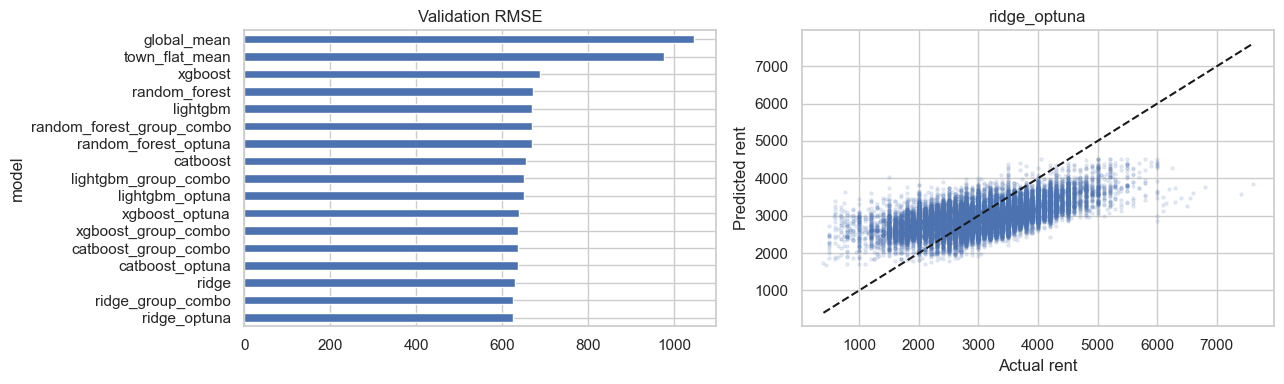

,rows,MAE,mean_residual
town,,,
bukit timah,117,742.98,166.24
central,561,579.65,171.40
jurong west,2507,561.57,88.95
pasir ris,979,553.69,212.15
bukit merah,1949,550.10,145.70
bishan,801,549.18,153.97
clementi,1264,547.96,73.32
tampines,2375,528.31,127.46
kallang/whampoa,1374,527.53,19.58


In [10]:
leaderboard.to_csv(RUN_DIR / 'validation_leaderboard.csv', index=False)
winner_name = str(leaderboard.iloc[0].model)
winner_spec = copy.deepcopy(fitted_bundles[winner_name]['spec'])
winner_prediction = validation_predictions[winner_name]
print('Selected model:', winner_name, '| Feature set:', winner_spec['feature_set'])
print('Selection uses validation only, not the independent holdout.')
validation_report = valid_data[['row_id', 'rent_approval_date', 'town', 'flat_type', 'floor_area_sqm']].copy()
validation_report['actual'] = y_valid
validation_report['prediction'] = winner_prediction
validation_report['residual'] = validation_report.actual - validation_report.prediction
validation_report['absolute_error'] = validation_report.residual.abs()
validation_report.to_csv(RUN_DIR / 'validation_predictions.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
leaderboard.set_index('model')[PRIMARY_METRIC].plot.barh(ax=axes[0], title=f'Validation {PRIMARY_METRIC}')
axes[1].scatter(y_valid, winner_prediction, s=5, alpha=.12)
lo, hi = float(y_valid.min()), float(y_valid.max())
axes[1].plot([lo, hi], [lo, hi], 'k--'); axes[1].set(xlabel='Actual rent', ylabel='Predicted rent', title=winner_name)
plt.tight_layout(); plt.show()
display(validation_report.groupby('town').agg(rows=('actual', 'size'), MAE=('absolute_error', 'mean'),
    mean_residual=('residual', 'mean')).sort_values('MAE', ascending=False).round(2))


## 9. One Independent Temporal Holdout Evaluation

The previously fixed configuration is retrained on all available records before 2024 and used to predict 2024–2025-03.

In fixed-origin mode, macroeconomic information for this evaluation is frozen at 2023-12. Quick mode is intended only for execution checks, and its sampled results are labeled separately.

,evaluation,quick_mode,model,kind,feature_set,RMSE,MAE,RMSLE,R2,input_features,fit_predict_seconds
0,independent_temporal_holdout,False,ridge_optuna,ridge,macro,527.4409,386.0739,0.2034,0.3709,71,4.3745


C:\Users\GabrielDai\AppData\Local\Temp\ipykernel_30904\1895468122.py:24: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  plt.ylabel('SGD/month'); plt.tight_layout(); plt.show()
d:\AppData\miniconda3\envs\cs5228\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
d:\AppData\miniconda3\envs\cs5228\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


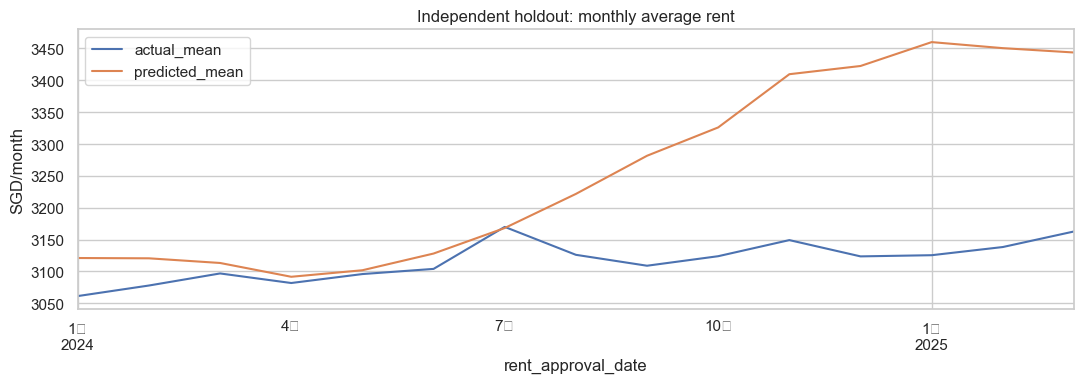

In [11]:
prehold_raw = train_features[train_features.rent_approval_date < HOLDOUT_START].copy()
if QUICK_MODE:
    prehold_raw = cap_rows(prehold_raw, 18000)
holdout_origin = prehold_raw.rent_approval_date.max()
prehold_data = attach_macro(prehold_raw, holdout_origin)
holdout_data = attach_macro(holdout_raw, holdout_origin)
y_prehold = y.loc[prehold_data.row_id].to_numpy()
y_holdout = y.loc[holdout_data.row_id].to_numpy()
holdout_row, holdout_bundle, holdout_prediction = evaluate_spec(
    winner_spec, prehold_data, y_prehold, holdout_data, y_holdout)
holdout_metrics = pd.DataFrame([{'evaluation': 'independent_temporal_holdout', 'quick_mode': QUICK_MODE, **holdout_row}])
holdout_metrics.to_csv(RUN_DIR / 'holdout_metrics.csv', index=False)
display(holdout_metrics.round(4))
holdout_report = holdout_data[['row_id', 'rent_approval_date', 'town', 'flat_type', 'floor_area_sqm']].copy()
holdout_report['actual'] = y_holdout
holdout_report['prediction'] = holdout_prediction
holdout_report['residual'] = holdout_report.actual - holdout_report.prediction
holdout_report['absolute_error'] = holdout_report.residual.abs()
holdout_report.to_csv(RUN_DIR / 'holdout_predictions.csv', index=False)
holdout_by_month = holdout_report.groupby('rent_approval_date').agg(
    actual_mean=('actual', 'mean'), predicted_mean=('prediction', 'mean'), MAE=('absolute_error', 'mean'))
holdout_by_month.to_csv(RUN_DIR / 'holdout_by_month.csv')
holdout_by_month[['actual_mean', 'predicted_mean']].plot(figsize=(11, 4), title='Independent holdout: monthly average rent')
plt.ylabel('SGD/month'); plt.tight_layout(); plt.show()


## 10. Optional Supplementary Rolling-origin Backtests

The selected configuration remains fixed while several earlier forecast origins are examined using only pre-2024 data. The results are used to assess stability and do not automatically change the final configuration.

This is a retrospective diagnostic rather than a new independent test, because some labels from these periods have already been used during model selection.


In [11]:
backtest_rows = []
if RUN_ROLLING_BACKTEST:
    for start in [pd.Timestamp('2022-07-01'), pd.Timestamp('2023-01-01'), pd.Timestamp('2023-07-01')]:
        end = min(start + pd.DateOffset(months=6), HOLDOUT_START)
        earlier = train_features[train_features.rent_approval_date < start].copy()
        later = train_features[(train_features.rent_approval_date >= start) & (train_features.rent_approval_date < end)].copy()
        if QUICK_MODE:
            earlier, later = cap_rows(earlier, 12000), cap_rows(later, 4000)
        origin = earlier.rent_approval_date.max()
        a, b = attach_macro(earlier, origin), attach_macro(later, origin)
        row, _, _ = evaluate_spec(winner_spec, a, y.loc[a.row_id].to_numpy(), b, y.loc[b.row_id].to_numpy())
        backtest_rows.append({'forecast_start': start.strftime('%Y-%m'), **row})
    pd.DataFrame(backtest_rows).to_csv(RUN_DIR / 'supplementary_backtest.csv', index=False)
    display(pd.DataFrame(backtest_rows).round(4))
else:
    print('Supplementary rolling-origin backtest skipped.')


Supplementary rolling-origin backtest skipped.


## 11. Retraining on the Full Training Set, Saving the Model, and Generating Test Predictions

Once the model, features, and parameters are fixed, full mode retrains on all 150,000 labeled records. The former validation and holdout data may now be included in the final fit, but they cannot be reused to calculate a score claimed to be independent.

The original test-row order is preserved. In quick mode, the final fit still uses a sample, and both the output directories and metadata are marked as quick.

In [12]:
final_raw = cap_rows(train_features, 25000) if QUICK_MODE else train_features.copy()
final_origin = train_features.rent_approval_date.max()
final_data = attach_macro(final_raw, final_origin)
test_data = attach_macro(test_features, final_origin)
final_bundle = fit_bundle(winner_spec, final_data, y.loc[final_data.row_id].to_numpy())
test_prediction = predict_bundle(final_bundle, test_data)
assert np.array_equal(test_data.row_id.to_numpy(), np.arange(len(test_features)))
prediction_table = pd.DataFrame({'row_id': test_data.row_id, 'MONTHLY_RENT': test_prediction})
prediction_table.to_csv(SUBMISSION_DIR / 'test_predictions.csv', index=False)
run_metadata = {
    'quick_mode': QUICK_MODE, 'selection_metric': PRIMARY_METRIC, 'macro_policy': MACRO_POLICY,
    'forecast_information_cutoff_month': final_origin.strftime('%Y-%m'),
    'selected_model_spec': winner_spec, 'final_train_rows': len(final_data), 'test_rows': len(test_data),
    'duplicate_policy': 'retain', 'feature_pipeline_version': feature_meta['feature_pipeline_version'],
    'source_sha256': feature_meta['source_sha256'], 'validation_boundaries': {
        'valid_start': VALID_START.strftime('%Y-%m'), 'holdout_start': HOLDOUT_START.strftime('%Y-%m')},
    'python': platform.python_version(), 'package_versions': {
        p: package_metadata.version(p) for p in ['numpy', 'pandas', 'scikit-learn', 'catboost', 'xgboost', 'lightgbm']}
}
final_bundle['run_metadata'] = run_metadata
joblib.dump(final_bundle, MODEL_DIR / 'selected_model.joblib', compress=3)
(RUN_DIR / 'run_metadata.json').write_text(json.dumps(run_metadata, indent=2), encoding='utf-8')
split_summary.to_csv(RUN_DIR / 'split_summary.csv', index=False)
display(prediction_table.head())
display(prediction_table.MONTHLY_RENT.describe().to_frame())
print('Final training rows:', len(final_data), '| Test predictions:', len(prediction_table))
print('Saved model and preprocessing together:', MODEL_DIR / 'selected_model.joblib')


,row_id,MONTHLY_RENT
0,0,2854.683671
1,1,3659.150806
2,2,3114.717802
3,3,3178.913852
4,4,3341.524340


,MONTHLY_RENT
count,50000.000000
mean,3402.741701
std,431.341702
min,1810.556091
25%,3107.482253
50%,3385.782969
75%,3661.973956
max,5568.883339


Final training rows: 150000 | Test predictions: 50000
Saved model and preprocessing together: d:\AppData\NUS\Sem1\5228 Knowledge Discovery and Data Mining\cs5228-hdb-rent-prediction\outputs\training\full_fixed_origin\models\selected_model.joblib


## 12. Feature Importance and Optional SHAP

Models fitted during the validation stage are used to interpret learned relationships, without treating explanations as causal conclusions. For models using one-hot encoding, feature importance is shown for the expanded columns. Ridge reports absolute coefficient values, which are not compared with tree-model importance values on the same scale.

Native feature importance measures can be biased. SHAP also explains model outputs rather than causal effects. SHAP is enabled only for supported tree models.


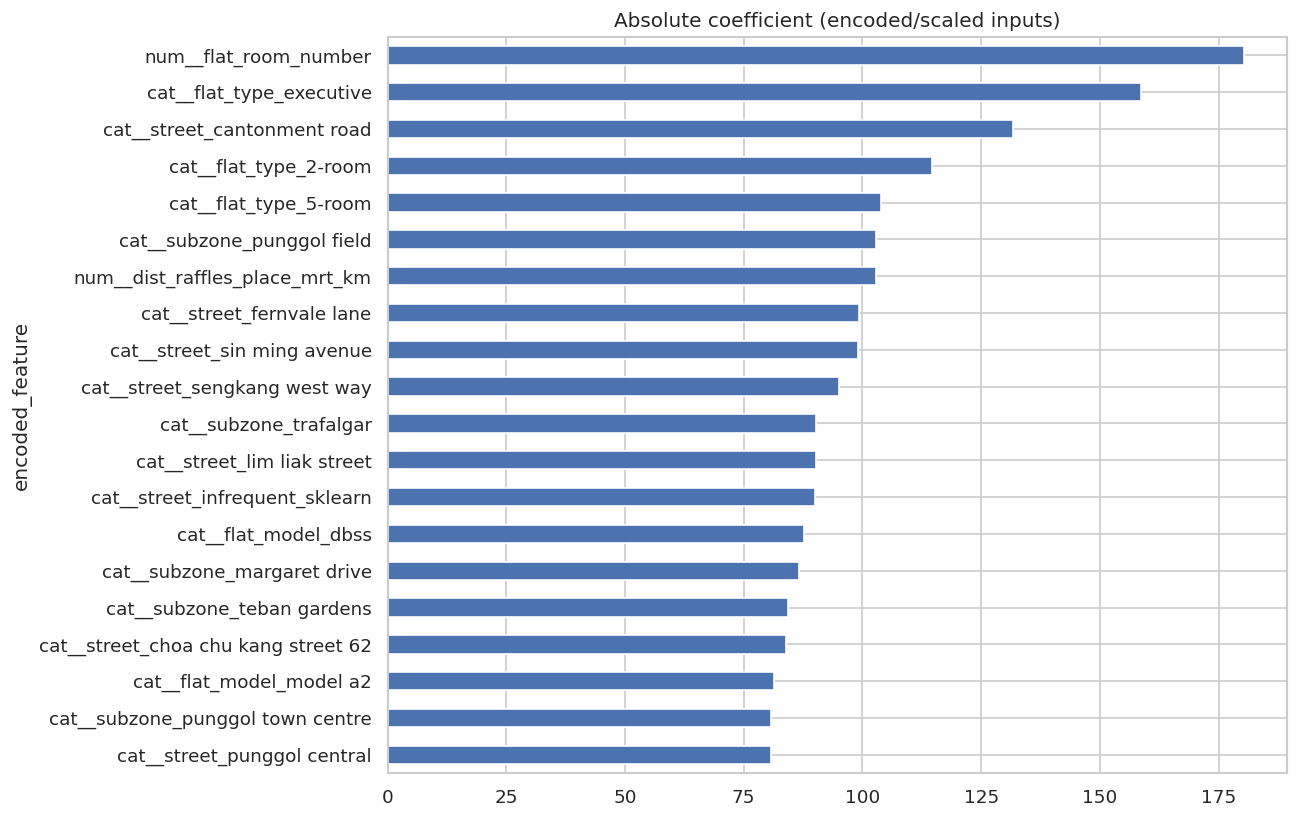

In [13]:
explanation_bundle = fitted_bundles[winner_name]
if 'pipeline' in explanation_bundle:
    pipe = explanation_bundle['pipeline']
    estimator = pipe.named_steps['model']
    names = pipe.named_steps['preprocess'].get_feature_names_out()
    if hasattr(estimator, 'feature_importances_'):
        values = np.asarray(estimator.feature_importances_)
        importance_label = 'Model feature importance'
    elif hasattr(estimator, 'coef_'):
        values = np.abs(np.asarray(estimator.coef_).ravel())
        importance_label = 'Absolute coefficient (encoded/scaled inputs)'
    else:
        values = None
    if values is not None:
        importance = pd.DataFrame({'encoded_feature': names, 'importance': values}).sort_values('importance', ascending=False)
        importance.to_csv(RUN_DIR / 'feature_importance.csv', index=False)
        importance.head(20).iloc[::-1].plot.barh(x='encoded_feature', y='importance', figsize=(11, 7), legend=False)
        plt.title(importance_label); plt.tight_layout(); plt.show()
    if RUN_SHAP and winner_spec['kind'] in ['catboost', 'xgboost', 'lightgbm', 'random_forest']:
        import shap
        sample = valid_data.sample(min(300, len(valid_data)), random_state=SEED)
        matrix = pipe.named_steps['preprocess'].transform(prepared_inputs(sample, explanation_bundle['columns']))
        if hasattr(matrix, 'toarray'):
            matrix = matrix.toarray()
        explainer = shap.TreeExplainer(estimator)
        shap_values = explainer.shap_values(matrix)
        shap.summary_plot(shap_values, matrix, feature_names=names, max_display=20, show=False)
        plt.tight_layout(); plt.show()
    elif RUN_SHAP:
        print('SHAP skipped for the selected non-tree model.')
else:
    print('The selected baseline has no encoded feature-importance vector.')


## 13. Creating an Official Submission Using the Actual Kaggle Template



In [13]:
# Prepare predictions.
prediction = np.asarray(test_prediction, dtype=float)
n_test = len(test_features)

assert prediction.shape == (n_test,), 'Prediction count or shape is incorrect.'
assert np.isfinite(prediction).all(), 'Predictions contain NaN or infinity.'
assert (prediction >= 0).all(), 'Predictions contain negative rent.'

# Confirm predictions follow the original test row order.
assert len(test_data) == n_test
assert np.array_equal(
    test_data['row_id'].to_numpy(),
    np.arange(n_test)
), 'Test rows are not in their original order.'

# Create the required Kaggle submission.
submission = pd.DataFrame({
    'Id': test_data['row_id'].to_numpy(dtype=np.int64),
    'Predicted': prediction
})

assert list(submission.columns) == ['Id', 'Predicted']
assert submission['Id'].is_unique

SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)
submission_path = SUBMISSION_DIR / (
    'submission_QUICK.csv' if QUICK_MODE else 'submission.csv'
)
submission.to_csv(submission_path, index=False)

display(submission.head())
print('Submission rows:', len(submission))
print('Saved to:', submission_path)


,Id,Predicted
0,0,2854.683671
1,1,3659.150806
2,2,3114.717802
3,3,3178.913852
4,4,3341.524340


Submission rows: 50000
Saved to: d:\AppData\NUS\Sem1\5228 Knowledge Discovery and Data Mining\cs5228-hdb-rent-prediction\submissions\full_fixed_origin\submission.csv


## 14. Results and Limitations to Discuss in the Report

1. How much do the models improve over the global-mean and group-mean baselines during the 2023 validation period? How do results change across feature tiers?
2. Are errors consistent between the validation period and the 15-month holdout? Does prediction become more difficult as the forecast horizon increases?
3. Are the importance patterns for floor area, flat type, location, and amenities plausible? Which Town / flat-type groups have larger errors?
4. MRT / mall / school data are static snapshots without historical opening dates. MAX_FLOOR describes building height rather than the floor of the individual rental unit.
5. Furnishing and fee fields are constant in this dataset, so their effects cannot be estimated. Renovation, the unit's exact floor, orientation, interior condition, and other attributes are also not fully described.
6. Freezing economic information at a fixed forecast origin and incorporating newly available data each month represent different information conditions. The report must state which assumption is used.
7. Local evaluation metrics may differ from the actual Kaggle metric. Kaggle test error cannot be reported without access to the true test labels.

API references: [scikit-learn OneHotEncoder](https://scikit-learn.org/1.6/modules/generated/sklearn.preprocessing.OneHotEncoder.html),
[SimpleImputer](https://scikit-learn.org/1.6/modules/generated/sklearn.impute.SimpleImputer.html),
[CatBoost](https://catboost.ai/docs/en/concepts/python-reference_catboostregressor),
[XGBoost](https://xgboost.readthedocs.io/en/release_3.0.0/python/python_api.html).
